<a href="https://colab.research.google.com/github/kokilahemachandra-afk/srilanka-ntl-midterm/blob/main/notebooks/07_spatial_markov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 · Mobility: do divisions move up, and do their neighbours matter?

β- and σ-convergence summarise the whole distribution. **Markov transitions** follow
each division: every year it sits in one of five light classes (Q1 = dimmest fifth,
Q5 = brightest fifth), and we count how often divisions move up, down or stay.

The **spatial Markov chain** (Rey, 2001) splits those moves by the class of the
division's **neighbours** (the average of divisions sharing a border), to test
whether a division's chances depend on where it is.

Variable: light per km² (`ntl_mean`), 2014–2025, 339 divisions → 11 year-to-year steps.

**Setup**

In [ ]:
!pip install -q "geo4bolivia[dynamics]"
import pandas as pd, numpy as np, geopandas as gpd
import matplotlib.pyplot as plt
import geo4bolivia as geo

plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
REPO = "https://raw.githubusercontent.com/kokilahemachandra-afk/srilanka-ntl-midterm/main/"
annual = pd.read_csv(REPO + "data/processed/lka_ds339_ntl_annual.csv")
shp = gpd.read_file(REPO + "data/boundaries/lka_admin3.shp")
gdf = shp.rename(columns={"adm3_pcode": "geo_id", "adm3_name": "name"})[["geo_id", "name", "geometry"]]

## Step M1 · How mobile are divisions? (classic Markov matrix)

Each row is this year's class; each cell is the probability of being in each class
next year. Classes are quintiles **within each year**, so a move up means overtaking
other divisions, not just getting brighter. The diagonal is the chance of staying.

In [ ]:
mk = geo.transitions(annual, "ntl_mean", k=5, per_year=True)
P = mk.p.round(3)
P.to_csv("markov_matrix.csv")
print("Chance of staying in the same class:", dict(zip(P.index, np.diag(P).round(2))))
P

Chance of staying in the same class: {'Q1': np.float64(0.88), 'Q2': np.float64(0.79), 'Q3': np.float64(0.84), 'Q4': np.float64(0.89), 'Q5': np.float64(0.96)}


,Q1,Q2,Q3,Q4,Q5
Q1,0.882,0.116,0.001,0.000,0.000
Q2,0.116,0.790,0.091,0.003,0.000
Q3,0.001,0.094,0.839,0.066,0.000
Q4,0.000,0.001,0.067,0.889,0.043
Q5,0.000,0.000,0.000,0.043,0.957


**Chart**

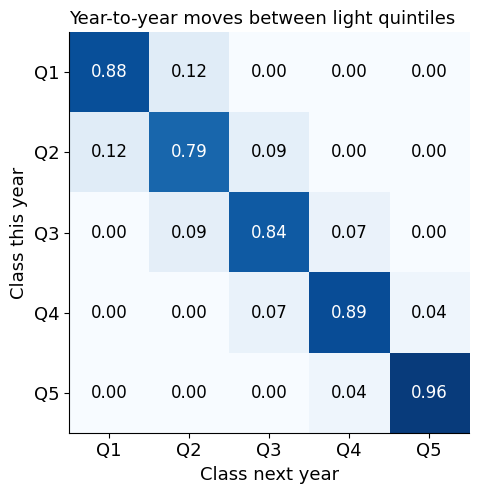

In [ ]:
fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.imshow(P.values, cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{P.values[i, j]:.2f}", ha="center", va="center", fontsize=12,
                color="white" if P.values[i, j] > 0.5 else "black")
ax.set_xticks(range(5)); ax.set_xticklabels(P.columns)
ax.set_yticks(range(5)); ax.set_yticklabels(P.index)
ax.set_xlabel("Class next year"); ax.set_ylabel("Class this year")
ax.set_title("Year-to-year moves between light quintiles", loc="left", fontsize=13)
plt.savefig("fig_markov_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

**Result:** positions are very persistent. In a given year, 79–96% of divisions stay
in their class, and almost every move is one step up or down. The brightest fifth
(Q5) is the most stable (96% stay). Catching up happens slowly, one step at a time.

## Step M2 · Do neighbours matter? (spatial Markov)

The same moves, split into five matrices by the neighbours' class. The tests ask
whether the five matrices are equal. If they are not, a division's mobility is
associated with its neighbours.

Here classes are levels relative to each year's national mean, pooled over all
years (the function's default), so they differ slightly from Step M1.

In [ ]:
sm = geo.spatial_transitions(annual, "ntl_mean", k=5, gdf=gdf)
print(f"Same dynamics in every neighbourhood?  LR = {sm.lr_stat:.0f}, p = {sm.lr_p:.3g}  |  "
      f"Q = {sm.q_stat:.0f}, p = {sm.q_p:.3g}  ({sm.dof} degrees of freedom)")   # LR 178, Q 236, p < 0.001

Same dynamics in every neighbourhood?  LR = 178, p = 1.11e-16  |  Q = 236, p = 0  (48 degrees of freedom)


## Step M3 · In which direction do neighbours matter?

The five 5×5 matrices are hard to read, and some cells rest on very few moves
(a dim division next to very bright ones is rare). So we summarise two questions,
with the number of moves (n) behind each figure:
- **Dim divisions (Q1–Q2):** how often do they move **up**, by neighbours' class?
- **Bright divisions (Q4–Q5):** how often do they move **down**?

Groups with fewer than 20 moves are left out of the chart (too few to trust).

In [ ]:
to_num = lambda s: s.astype(str).str[1].astype(int)          # "Q3" → 3
moves = sm.df.sort_values(["geo_id", "year"]).copy()
moves["next_state"] = moves.groupby("geo_id")["state"].shift(-1)
moves = moves.dropna(subset=["next_state"])                  # last year has no "next"
moves["own"] = to_num(moves["state"])
moves["nbr"] = to_num(moves["neighbor_state"])
moves["change"] = np.sign(to_num(moves["next_state"]) - moves["own"])   # +1 up, 0 stay, −1 down

summarise = lambda d: d.groupby("nbr")["change"].agg(
    moves="count", up=lambda s: (s > 0).mean(), down=lambda s: (s < 0).mean()).round(3)
dim, bright = summarise(moves[moves["own"] <= 2]), summarise(moves[moves["own"] >= 4])
dim.index = [f"Q{i}" for i in dim.index]
bright.index = [f"Q{i}" for i in bright.index]
pd.concat({"dim_Q1_Q2": dim, "bright_Q4_Q5": bright}).to_csv("spatial_markov_by_neighbours.csv")
print("Dim divisions:"); print(dim)
print("Bright divisions:"); print(bright)

Dim divisions:
    moves     up   down
Q1    690  0.299  0.057
Q2    505  0.214  0.135
Q3    241  0.328  0.133
Q4     59  0.373  0.034
Q5      7  0.571  0.000
Bright divisions:
    moves     up   down
Q1     34  0.029  0.088
Q2     56  0.018  0.179
Q3    165  0.012  0.079
Q4    499  0.024  0.050
Q5    726  0.017  0.017


**Chart**

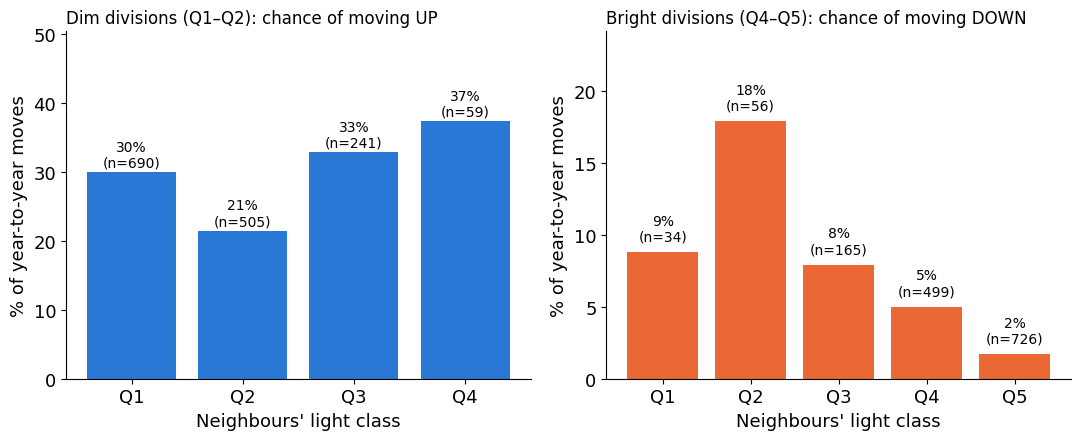

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
panels = [(axes[0], dim, "up", "#2a78d6", "Dim divisions (Q1–Q2): chance of moving UP"),
          (axes[1], bright, "down", "#eb6834", "Bright divisions (Q4–Q5): chance of moving DOWN")]
for ax, tab, col, colour, title in panels:
    keep = tab["moves"] >= 20
    ax.bar(tab.index[keep], tab.loc[keep, col] * 100, color=colour)
    for x, (v, n) in enumerate(zip(tab.loc[keep, col], tab.loc[keep, "moves"])):
        ax.text(x, v * 100 + 0.8, f"{v*100:.0f}%\n(n={n})", ha="center", fontsize=10)
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel("Neighbours' light class")
    ax.set_ylabel("% of year-to-year moves")
    ax.set_ylim(0, tab.loc[keep, col].max() * 100 * 1.35)
plt.tight_layout()
plt.savefig("fig_spatial_markov.png", dpi=200, bbox_inches="tight")
plt.show()

**Result:** neighbours matter (LR and Q tests, p < 0.001), in two ways:
- **Bright divisions slip when their neighbours are dim.** A Q4–Q5 division with
  Q2 neighbours moved down in 18% of years, against 2% for one surrounded by Q5
  neighbours. Brightness is most stable inside bright clusters.
- **Dim divisions get a modest lift from brighter neighbours.** Dim divisions moved
  up in 33–37% of years when their neighbours were in Q3–Q4, against 21–30% with
  Q1–Q2 neighbours. But few dim divisions have bright neighbours (300 of about
  1,500 moves), so the effect reaches only a small part of the country.

**Interpretation:** this fits the LISA and club results: the bright Colombo cluster
holds its place, while most dim divisions sit among other dim divisions, where the
chance of moving up is lowest. These are associations, not causes, and again
they concern light, not yet living standards (notebook 04).

**Download**

In [ ]:
from google.colab import files
for f in ["markov_matrix.csv", "spatial_markov_by_neighbours.csv",
          "fig_markov_matrix.png", "fig_spatial_markov.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>